In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets
df_trading = pd.read_csv(r"C:\Users\preeti123\Desktop\PREETI\training project2\project2_trading.csv")
df_instruments = pd.read_csv(r"C:\Users\preeti123\Desktop\PREETI\training project2\project2_instruments.csv")

df_trading['slippage_usd'] = (df_trading['slippage_bps'] / 10000) * df_trading['execution_price'] * df_trading['quantity']
df_trading['market_impact_usd'] = (df_trading['market_impact_bps'] / 10000) * df_trading['execution_price'] * df_trading['quantity']
df_trading['total_trading_cost_usd'] = (df_trading['slippage_usd'] + df_trading['commission_usd'])

df_trading

,trade_id,instrument_id,timestamp,trade_type,order_type,strategy,quantity,price,execution_price,slippage_bps,...,unrealized_pnl_usd,position_size,portfolio_weight,var_contribution,expected_shortfall,alpha,information_ratio,slippage_usd,market_impact_usd,total_trading_cost_usd
0,TRD_000001,INST_00516,2024-01-01 00:00:00.000000000,SELL,MARKET,PAIRS_TRADING,86786,2366.97821,4228.99805,45.69314,...,33727.55083,-5426,-0.01920,9951.04505,3630.84649,0.04146,-0.51585,1677019.82386,995618.24357,1677143.38147
1,TRD_000002,INST_00818,2024-01-01 00:11:39.863328777,BUY,LIMIT,PAIRS_TRADING,44460,245.02027,1939.50047,-13.85611,...,5674.83862,22693,-0.04963,7307.21553,6161.01607,-0.00795,-1.32433,-119481.51868,39584.00400,-119175.56893
2,TRD_000003,INST_00283,2024-01-01 00:23:19.726657555,BUY,LIMIT,ARBITRAGE,69063,1182.44910,2909.05235,13.28507,...,-8033.11364,16986,-0.03129,964.66053,7325.32768,0.03011,2.97339,266907.43204,272109.69469,267347.29451
3,TRD_000004,INST_00138,2024-01-01 00:34:59.589986332,SELL,STOP_LIMIT,PAIRS_TRADING,5099,3582.86499,717.50019,19.82552,...,39938.15979,-5105,-0.09765,4481.30959,14672.75007,0.00117,0.47156,7253.23277,2941.02857,7404.48944
4,TRD_000005,INST_00931,2024-01-01 00:46:39.453315110,SELL,MARKET,MARKET_MAKING,16791,434.69801,3995.29158,-20.16125,...,-2649.71197,-18134,0.03541,2501.40763,4633.07179,0.03596,-0.41563,-135251.63992,89446.88216,-135057.07235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,TRD_029996,INST_01363,2024-08-30 23:13:20.546684892,SELL,STOP,PAIRS_TRADING,20224,118.43509,4354.70130,26.05441,...,-1635.97005,-44959,-0.04504,5412.15266,13337.09684,0.00471,1.85090,229459.81601,30050.36083,229631.21945
29996,TRD_029997,INST_00330,2024-08-30 23:25:00.410013668,BUY,MARKET,MOMENTUM,26314,1848.21670,3807.40825,-44.57297,...,-9602.89534,-10400,-0.06806,1947.20569,1876.60429,0.04578,2.34539,-446568.27062,109145.18700,-446557.64060
29997,TRD_029998,INST_01194,2024-08-30 23:36:40.273342448,SELL,LIMIT,MARKET_MAKING,80769,2239.60161,4098.30897,36.58651,...,32951.07367,13081,0.01642,6992.48332,2787.58858,0.02577,-0.65959,1211073.10358,594431.97692,1211325.93341
29998,TRD_029999,INST_01480,2024-08-30 23:48:20.136671224,SELL,STOP_LIMIT,MEAN_REVERSION,98767,549.47755,3853.54834,16.16166,...,-2577.31134,-23868,-0.04790,8904.90287,9859.83870,0.03070,-1.65213,615118.36361,732258.81465,615587.38196


In [29]:
# Merge to get asset_class & sector
df_merged = pd.merge(df_trading, df_instruments[['instrument_id', 'asset_class', 'sector']], 
                     on='instrument_id', how='left')

# Relevant columns
tca_df = df_merged[['timestamp', 'instrument_id','strategy', 'asset_class', 'sector', 'slippage_bps', 'slippage_usd', 'market_impact_bps',
                    'market_impact_usd', 'commission_usd', 'total_trading_cost_usd', 'pnl_usd', 'unrealized_pnl_usd']]

tca_df

,timestamp,instrument_id,strategy,asset_class,sector,slippage_bps,slippage_usd,market_impact_bps,market_impact_usd,commission_usd,total_trading_cost_usd,pnl_usd,unrealized_pnl_usd
0,2024-01-01 00:00:00.000000000,INST_00516,PAIRS_TRADING,Commodity,Financial,45.69314,1677019.82386,27.12724,995618.24357,123.55761,1677143.38147,6303.27941,33727.55083
1,2024-01-01 00:11:39.863328777,INST_00818,PAIRS_TRADING,Fixed Income,Technology,-13.85611,-119481.51868,4.59050,39584.00400,305.94975,-119175.56893,-18609.69785,5674.83862
2,2024-01-01 00:23:19.726657555,INST_00283,ARBITRAGE,Crypto,Consumer,13.28507,266907.43204,13.54400,272109.69469,439.86247,267347.29451,24114.39200,-8033.11364
3,2024-01-01 00:34:59.589986332,INST_00138,PAIRS_TRADING,FX,Healthcare,19.82552,7253.23277,8.03882,2941.02857,151.25667,7404.48944,85492.85814,39938.15979
4,2024-01-01 00:46:39.453315110,INST_00931,MARKET_MAKING,Fixed Income,Energy,-20.16125,-135251.63992,13.33338,89446.88216,194.56757,-135057.07235,-27824.69395,-2649.71197
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,2024-08-30 23:13:20.546684892,INST_01363,PAIRS_TRADING,FX,Energy,26.05441,229459.81601,3.41212,30050.36083,171.40344,229631.21945,59105.26483,-1635.97005
29996,2024-08-30 23:25:00.410013668,INST_00330,MOMENTUM,Crypto,Technology,-44.57297,-446568.27062,10.89402,109145.18700,10.63002,-446557.64060,40554.99184,-9602.89534
29997,2024-08-30 23:36:40.273342448,INST_01194,MARKET_MAKING,FX,Technology,36.58651,1211073.10358,17.95778,594431.97692,252.82983,1211325.93341,-39883.22692,32951.07367
29998,2024-08-30 23:48:20.136671224,INST_01480,MEAN_REVERSION,FX,Healthcare,16.16166,615118.36361,19.23942,732258.81465,469.01835,615587.38196,63890.90058,-2577.31134


In [31]:
# Basic statistics for each metric
tca_summary = tca_df.describe()
tca_summary

,slippage_bps,slippage_usd,market_impact_bps,market_impact_usd,commission_usd,total_trading_cost_usd,pnl_usd,unrealized_pnl_usd
count,30000.00000,30000.00000,30000.00000,30000.00000,30000.00000,30000.00000,30000.00000,30000.00000
mean,0.09505,5204.10322,15.01957,187928.78732,250.69224,5454.79546,24621.11443,12343.09786
std,28.81255,481183.26643,8.64698,219158.19587,143.74680,481181.99592,43355.02653,21576.55763
min,-49.99995,-2379662.76981,0.00238,0.82212,1.00352,-2379644.64140,-49999.21289,-24998.29597
25%,-25.03081,-175658.83521,7.59286,30714.98203,127.01142,-175426.09310,-13122.95603,-6295.58081
50%,0.27591,263.79982,14.94431,104866.78254,249.78141,513.89600,24610.95569,12224.79558
75%,25.14608,175527.42565,22.49504,266294.53321,375.46255,175790.08213,62034.40133,30956.59752
max,49.99983,2419076.63930,29.99896,1398009.45244,499.98799,2419101.54974,99998.41479,49998.84336


In [57]:
# Average costs by instrument
cost_by_instrument = tca_df.groupby('instrument_id').mean(numeric_only=True)
cost_by_instrument

,slippage_bps,slippage_usd,market_impact_bps,market_impact_usd,commission_usd,total_trading_cost_usd,pnl_usd,unrealized_pnl_usd
instrument_id,,,,,,,,
INST_00001,17.52011,241826.42212,14.52213,193574.01394,290.10427,242116.52639,30696.26734,6105.32754
INST_00002,2.02142,-52513.15108,15.66944,124938.14403,289.28324,-52223.86784,18832.96635,16456.77568
INST_00003,-1.78977,-28038.78533,12.00777,152343.44639,274.66361,-27764.12173,35308.79042,5557.15582
INST_00004,0.51141,-57567.07779,14.77828,184991.04855,295.52931,-57271.54848,21907.81594,9159.43036
INST_00005,3.91154,87181.36282,11.95447,188654.96766,310.33122,87491.69405,16289.64322,16730.95838
...,...,...,...,...,...,...,...,...
INST_01496,-2.10069,-47954.18460,15.69001,160900.17270,256.48246,-47697.70214,18900.27205,9577.41092
INST_01497,5.11131,166608.89978,17.02372,254165.19220,276.13393,166885.03372,32551.29371,15823.42696
INST_01498,-4.70069,4596.51566,17.19043,179262.27522,266.65437,4863.17004,29354.32657,24217.74052


In [38]:
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)

               slippage_bps  slippage_usd  market_impact_bps  \
instrument_id                                                  
INST_00462          0.74454   71960.49712           17.21420   
INST_00236         -5.47823  -90373.66608           13.13906   
INST_01165          4.91185   44668.90362           16.60206   
INST_00392          4.93320   54174.98204           13.74963   
INST_00722         -1.16057   89308.79500           16.94103   
INST_00535         13.96160  219755.23153           14.46084   
INST_01041         -9.89308 -206258.83578           17.72386   
INST_01491          2.80795   23826.79603           13.44556   
INST_01373          4.93324  138157.24190           14.11872   
INST_00431          0.81963    2026.68383           13.01203   

               market_impact_usd  commission_usd  total_trading_cost_usd  \
instrument_id                                                              
INST_00462          139219.49173       278.60928             72239.10640   
INS

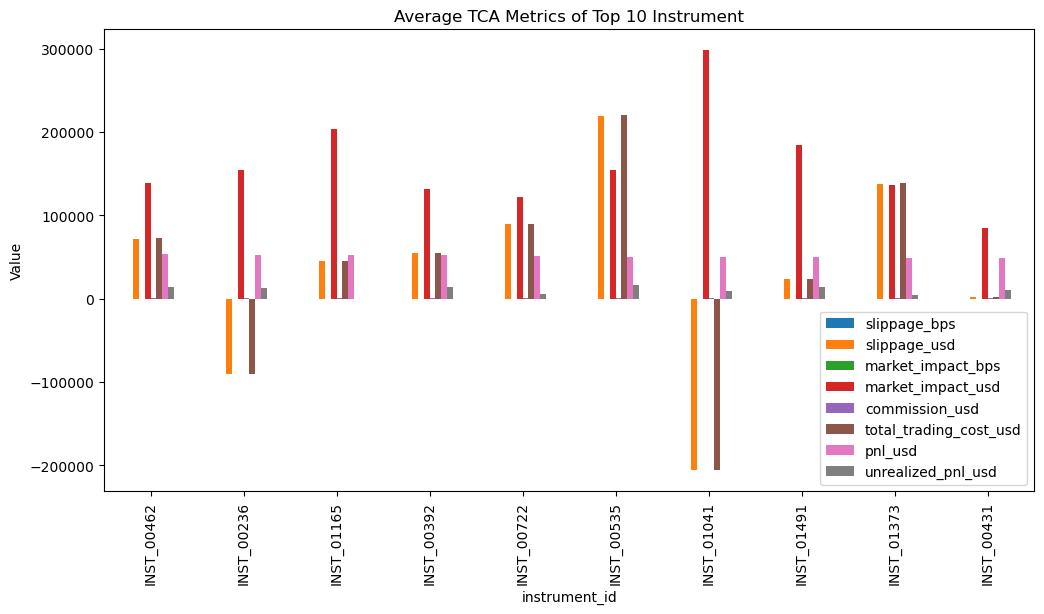

In [59]:
# top profitable instruments
top_instruments = cost_by_instrument.sort_values(by="pnl_usd",ascending=False).head(10)
print(top_instruments)

#PLot
top_instruments.plot(kind='bar', figsize=(12,6), title="Average TCA Metrics of Top 10 Instrument")
plt.ylabel("Value")
plt.show()

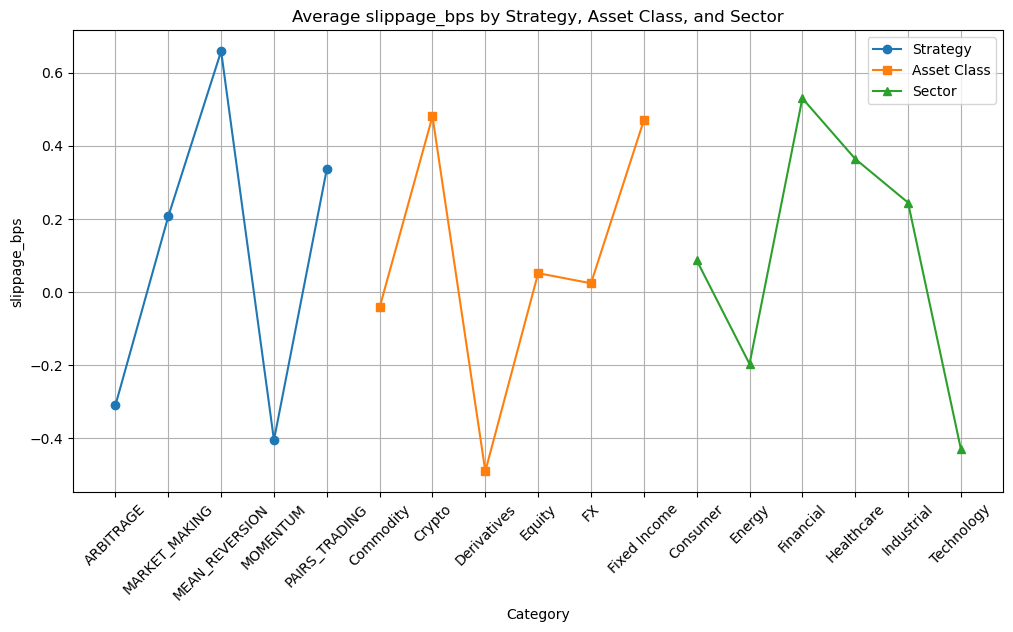

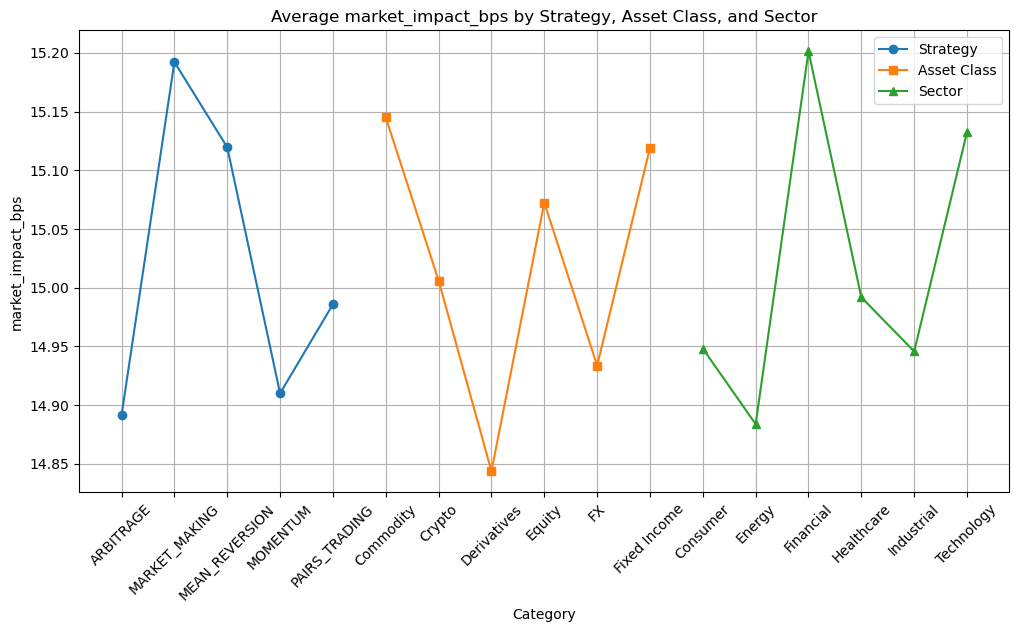

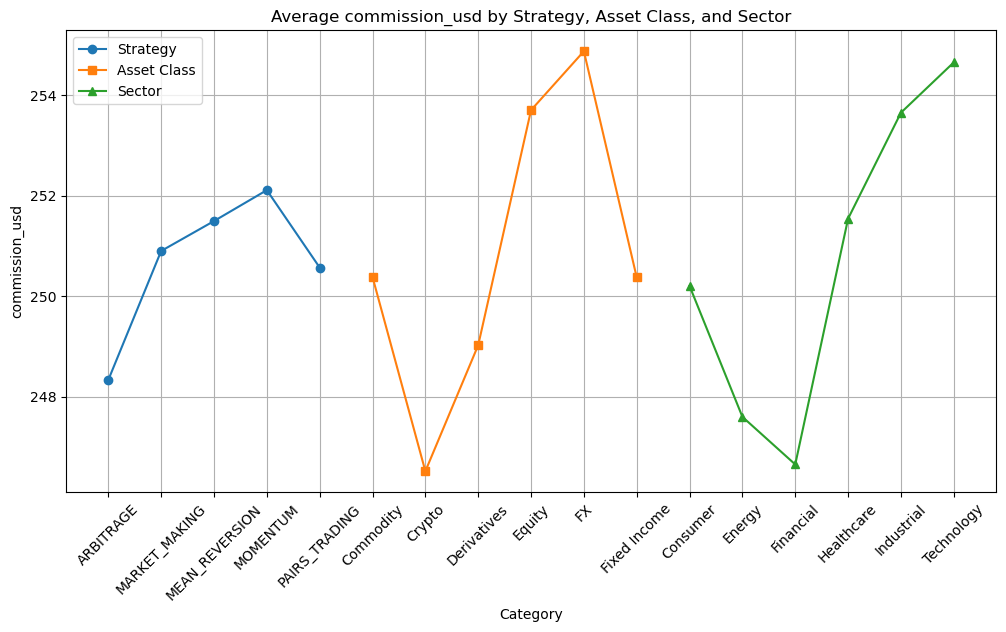

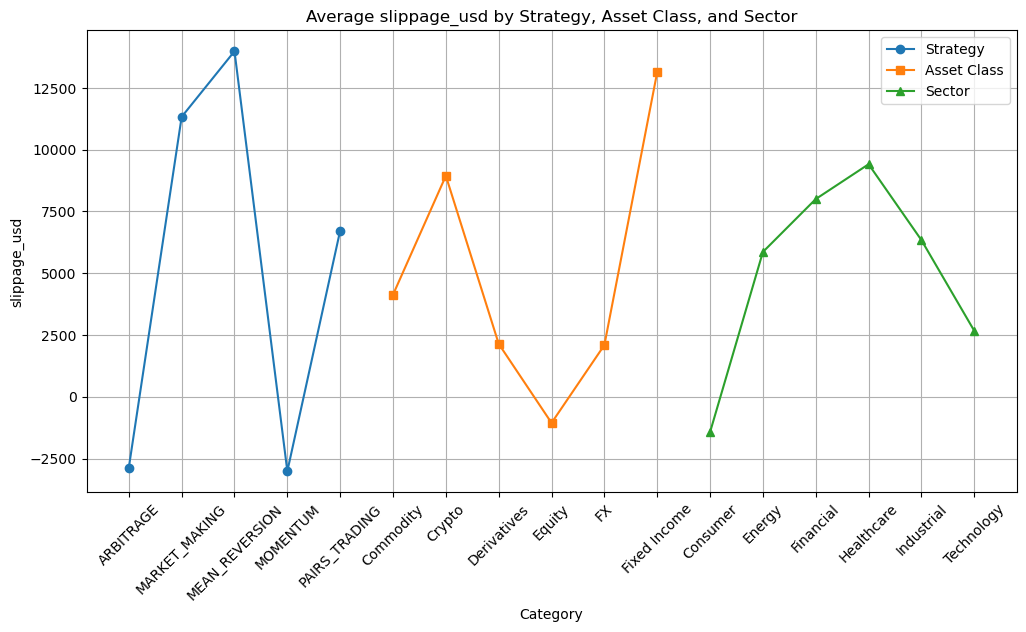

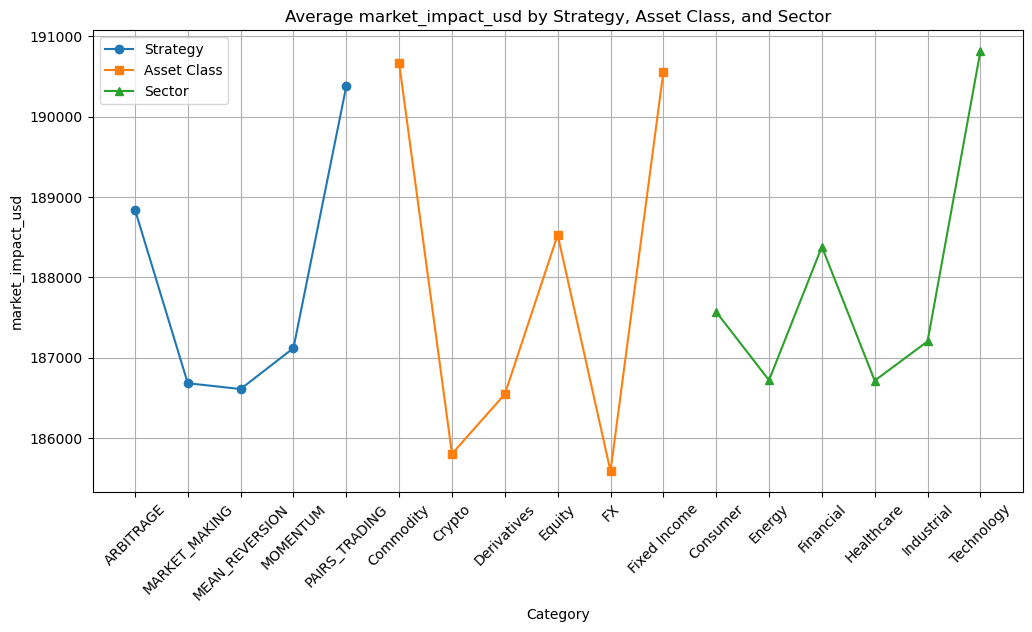

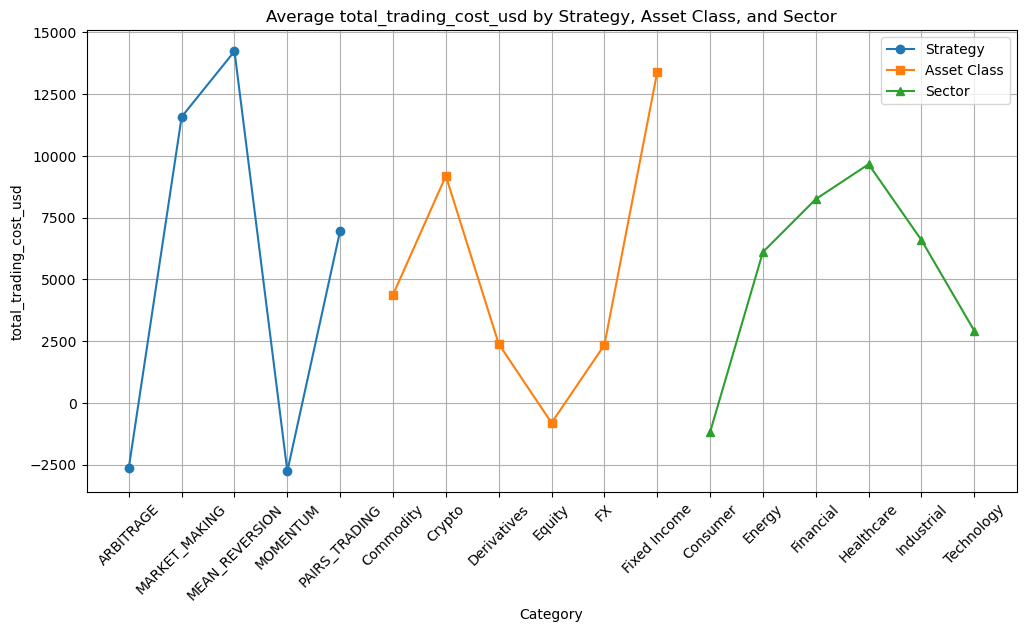

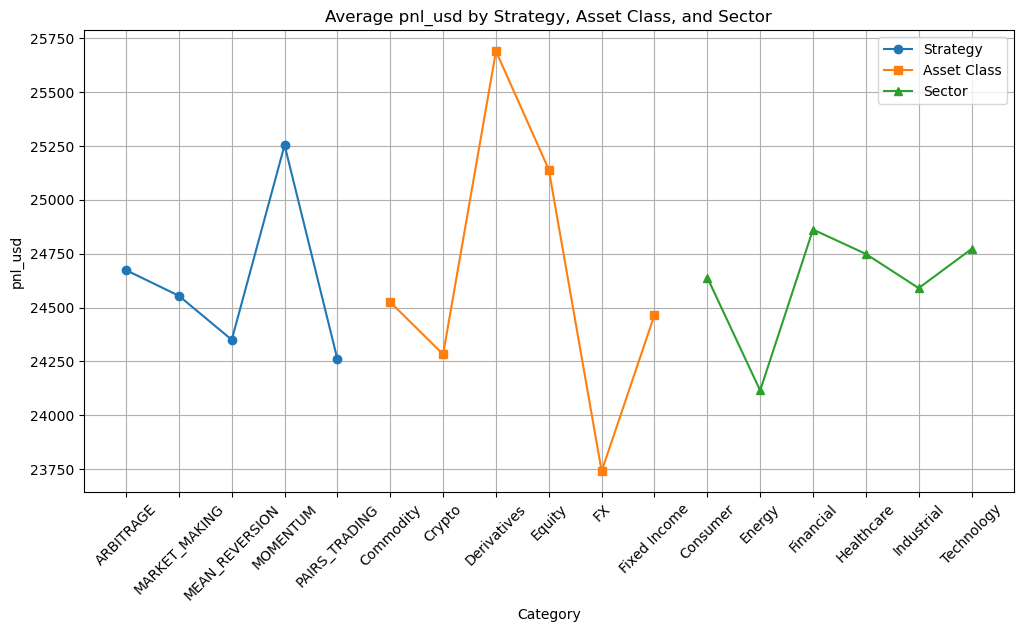

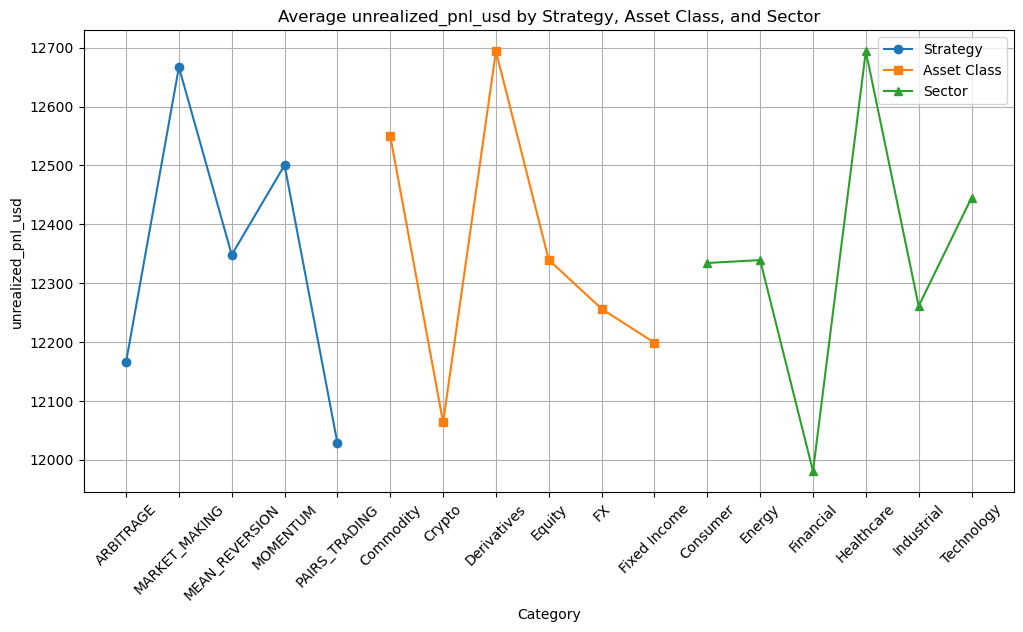

In [35]:
# --- Function to plot line chart for a given metric ---
def plot_metric(metric_name):
    plt.figure(figsize=(12,6))
    
    # Group by strategy
    strat = tca_df.groupby('strategy')[metric_name].mean()
    plt.plot(strat.index, strat.values, marker='o', label="Strategy")
    
    # Group by asset class
    asset = tca_df.groupby('asset_class')[metric_name].mean()
    plt.plot(asset.index, asset.values, marker='s', label="Asset Class")
    
    # Group by sector
    sector = tca_df.groupby('sector')[metric_name].mean()
    plt.plot(sector.index, sector.values, marker='^', label="Sector")
    
    plt.title(f"Average {metric_name} by Strategy, Asset Class, and Sector")
    plt.xlabel("Category")
    plt.ylabel(metric_name)
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.show()

# --- Create line charts for each metric ---
for metric in ['slippage_bps', 'market_impact_bps', 'commission_usd', 'slippage_usd', 'market_impact_usd', 'total_trading_cost_usd',
               'pnl_usd', 'unrealized_pnl_usd']:
    plot_metric(metric)


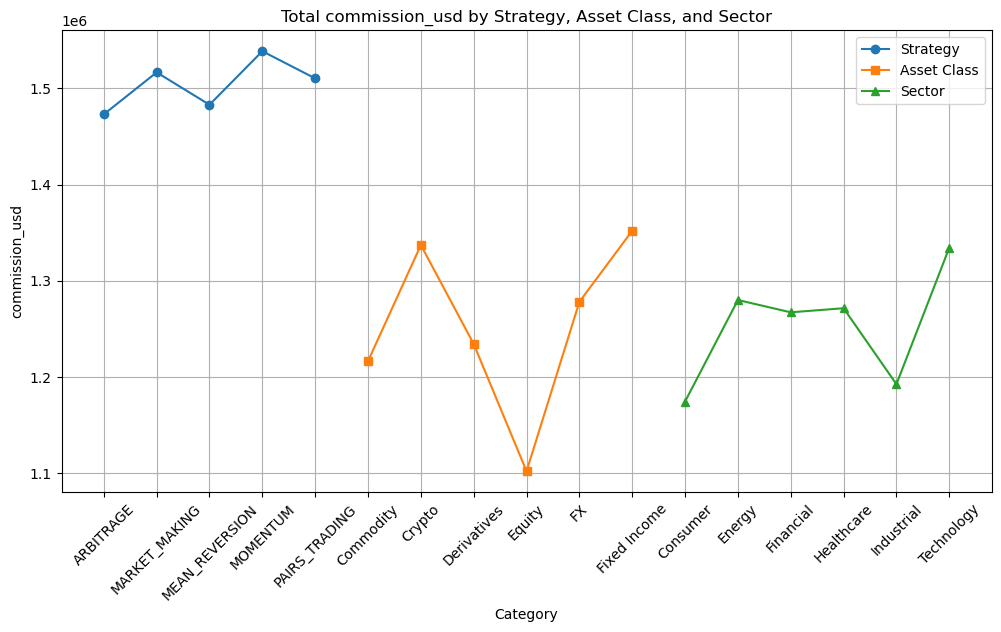

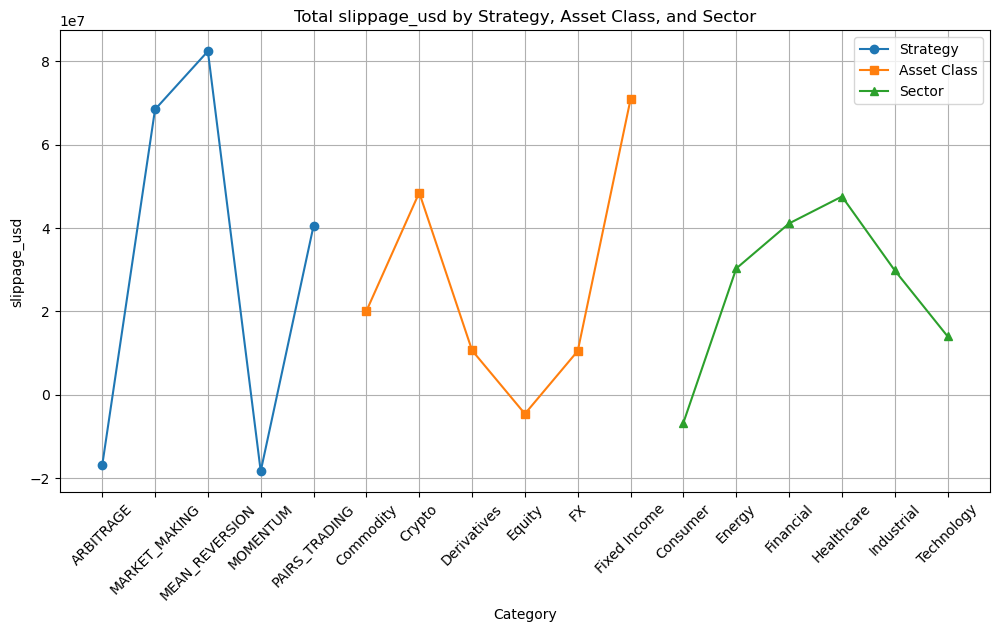

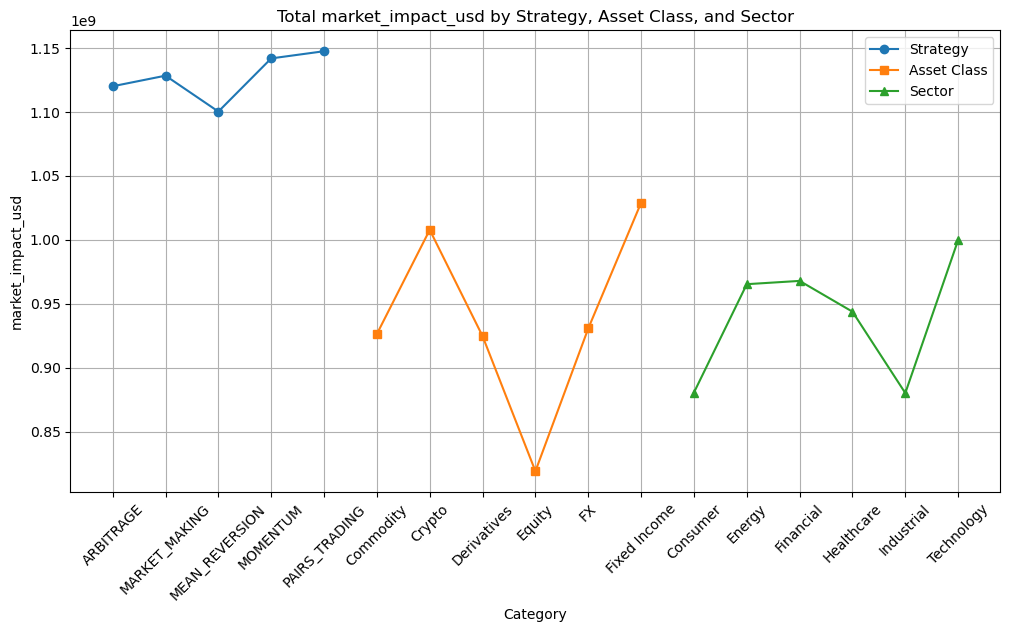

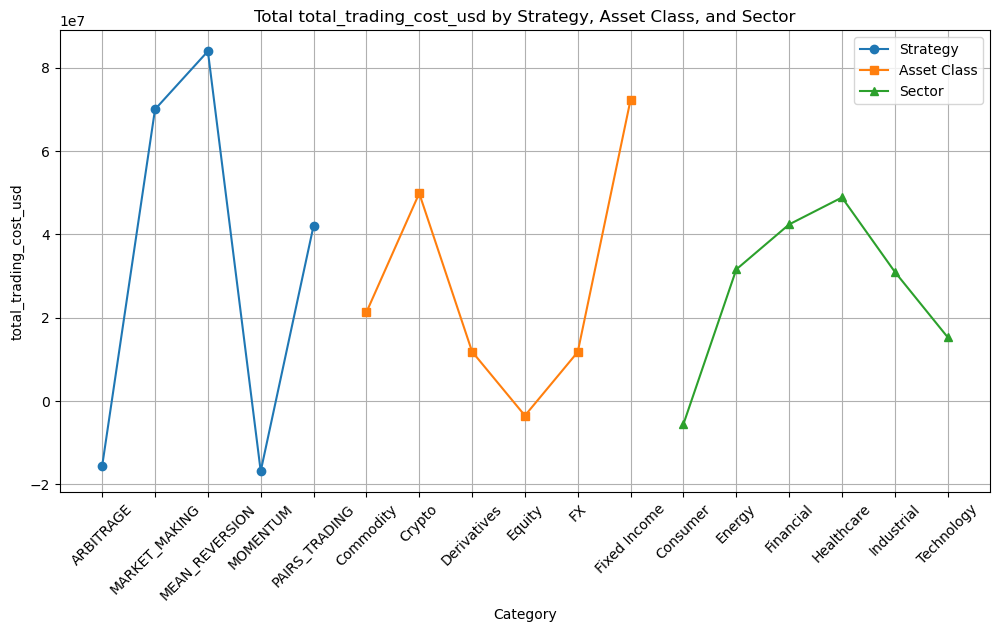

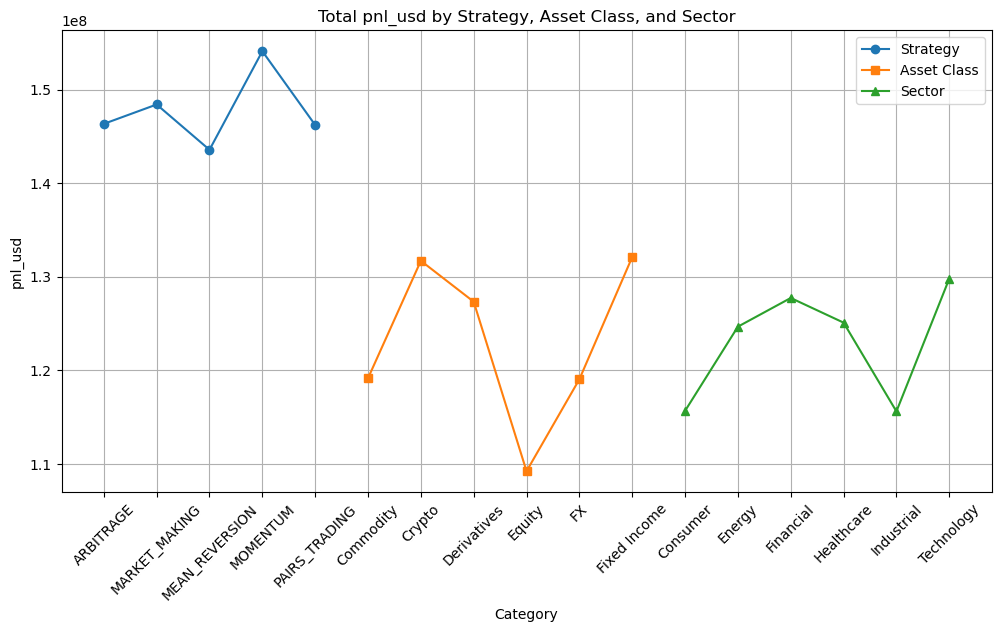

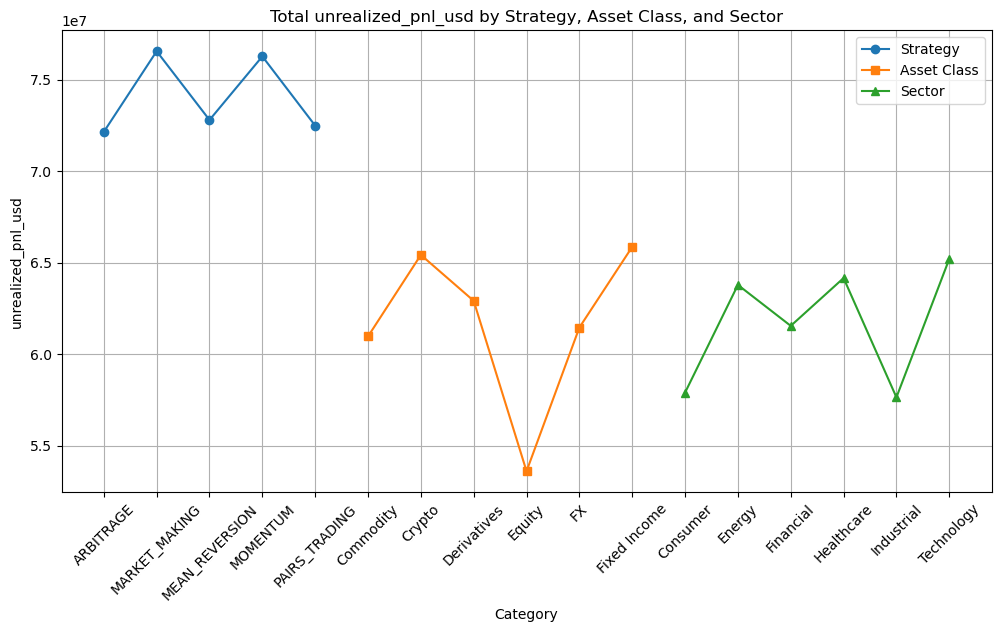

In [41]:
# --- Function to plot line chart for a given metric ---
def plot_metric(metric_name):
    plt.figure(figsize=(12,6))
    
    # Group by strategy
    strat = tca_df.groupby('strategy')[metric_name].sum()
    plt.plot(strat.index, strat.values, marker='o', label="Strategy")
    
    # Group by asset class
    asset = tca_df.groupby('asset_class')[metric_name].sum()
    plt.plot(asset.index, asset.values, marker='s', label="Asset Class")
    
    # Group by sector
    sector = tca_df.groupby('sector')[metric_name].sum()
    plt.plot(sector.index, sector.values, marker='^', label="Sector")
    
    plt.title(f"Total {metric_name} by Strategy, Asset Class, and Sector")
    plt.xlabel("Category")
    plt.ylabel(metric_name)
    plt.legend()
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.show()

# --- Create line charts for each metric ---
for metric in ['commission_usd', 'slippage_usd', 'market_impact_usd', 'total_trading_cost_usd',
               'pnl_usd', 'unrealized_pnl_usd']:
    plot_metric(metric)


In [45]:
# Convert timestamp → datetime
tca_df["timestamp"] = pd.to_datetime(tca_df["timestamp"], errors="coerce")
tca_df["week"] = tca_df["timestamp"].dt.strftime("%Y-%U")

# Weekly grouping
weekly = tca_df.groupby("week").agg(
    avg_slippage_bps=("slippage_bps","mean"),
    total_slippage_usd=("slippage_usd","sum"),
    total_commission_usd=("commission_usd","sum"),
    avg_market_impact_bps=("market_impact_bps","mean"),
    total_market_impact_usd=("market_impact_usd","sum"),
    total_pnl_usd=("pnl_usd","sum"),
    total_unrealized_pnl_usd=('unrealized_pnl_usd','sum')
).reset_index()

weekly.head()

C:\Users\preeti123\AppData\Local\Temp\ipykernel_20640\3977701248.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tca_df["timestamp"] = pd.to_datetime(tca_df["timestamp"], errors="coerce")
C:\Users\preeti123\AppData\Local\Temp\ipykernel_20640\3977701248.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  tca_df["week"] = tca_df["timestamp"].dt.strftime("%Y-%U")


,week,avg_slippage_bps,total_slippage_usd,total_commission_usd,avg_market_impact_bps,total_market_impact_usd,total_pnl_usd,total_unrealized_pnl_usd
0,2024-00,0.65548,29646726.62225,184037.19554,14.93666,145215907.14658,18039408.78012,8671227.56581
1,2024-01,-0.56757,-15430581.92972,207198.73936,15.40579,176227767.63327,22725358.77333,11650933.08706
2,2024-02,0.86764,3327795.36376,219376.93765,14.99933,161462012.41554,21719851.67011,10822430.76792
3,2024-03,-0.26835,-20198464.17935,214347.74262,14.87988,150053808.10768,20730276.53675,10688236.65415
4,2024-04,1.38401,21815372.15826,213566.55313,15.19045,158109075.23435,21310524.15011,11310592.65451


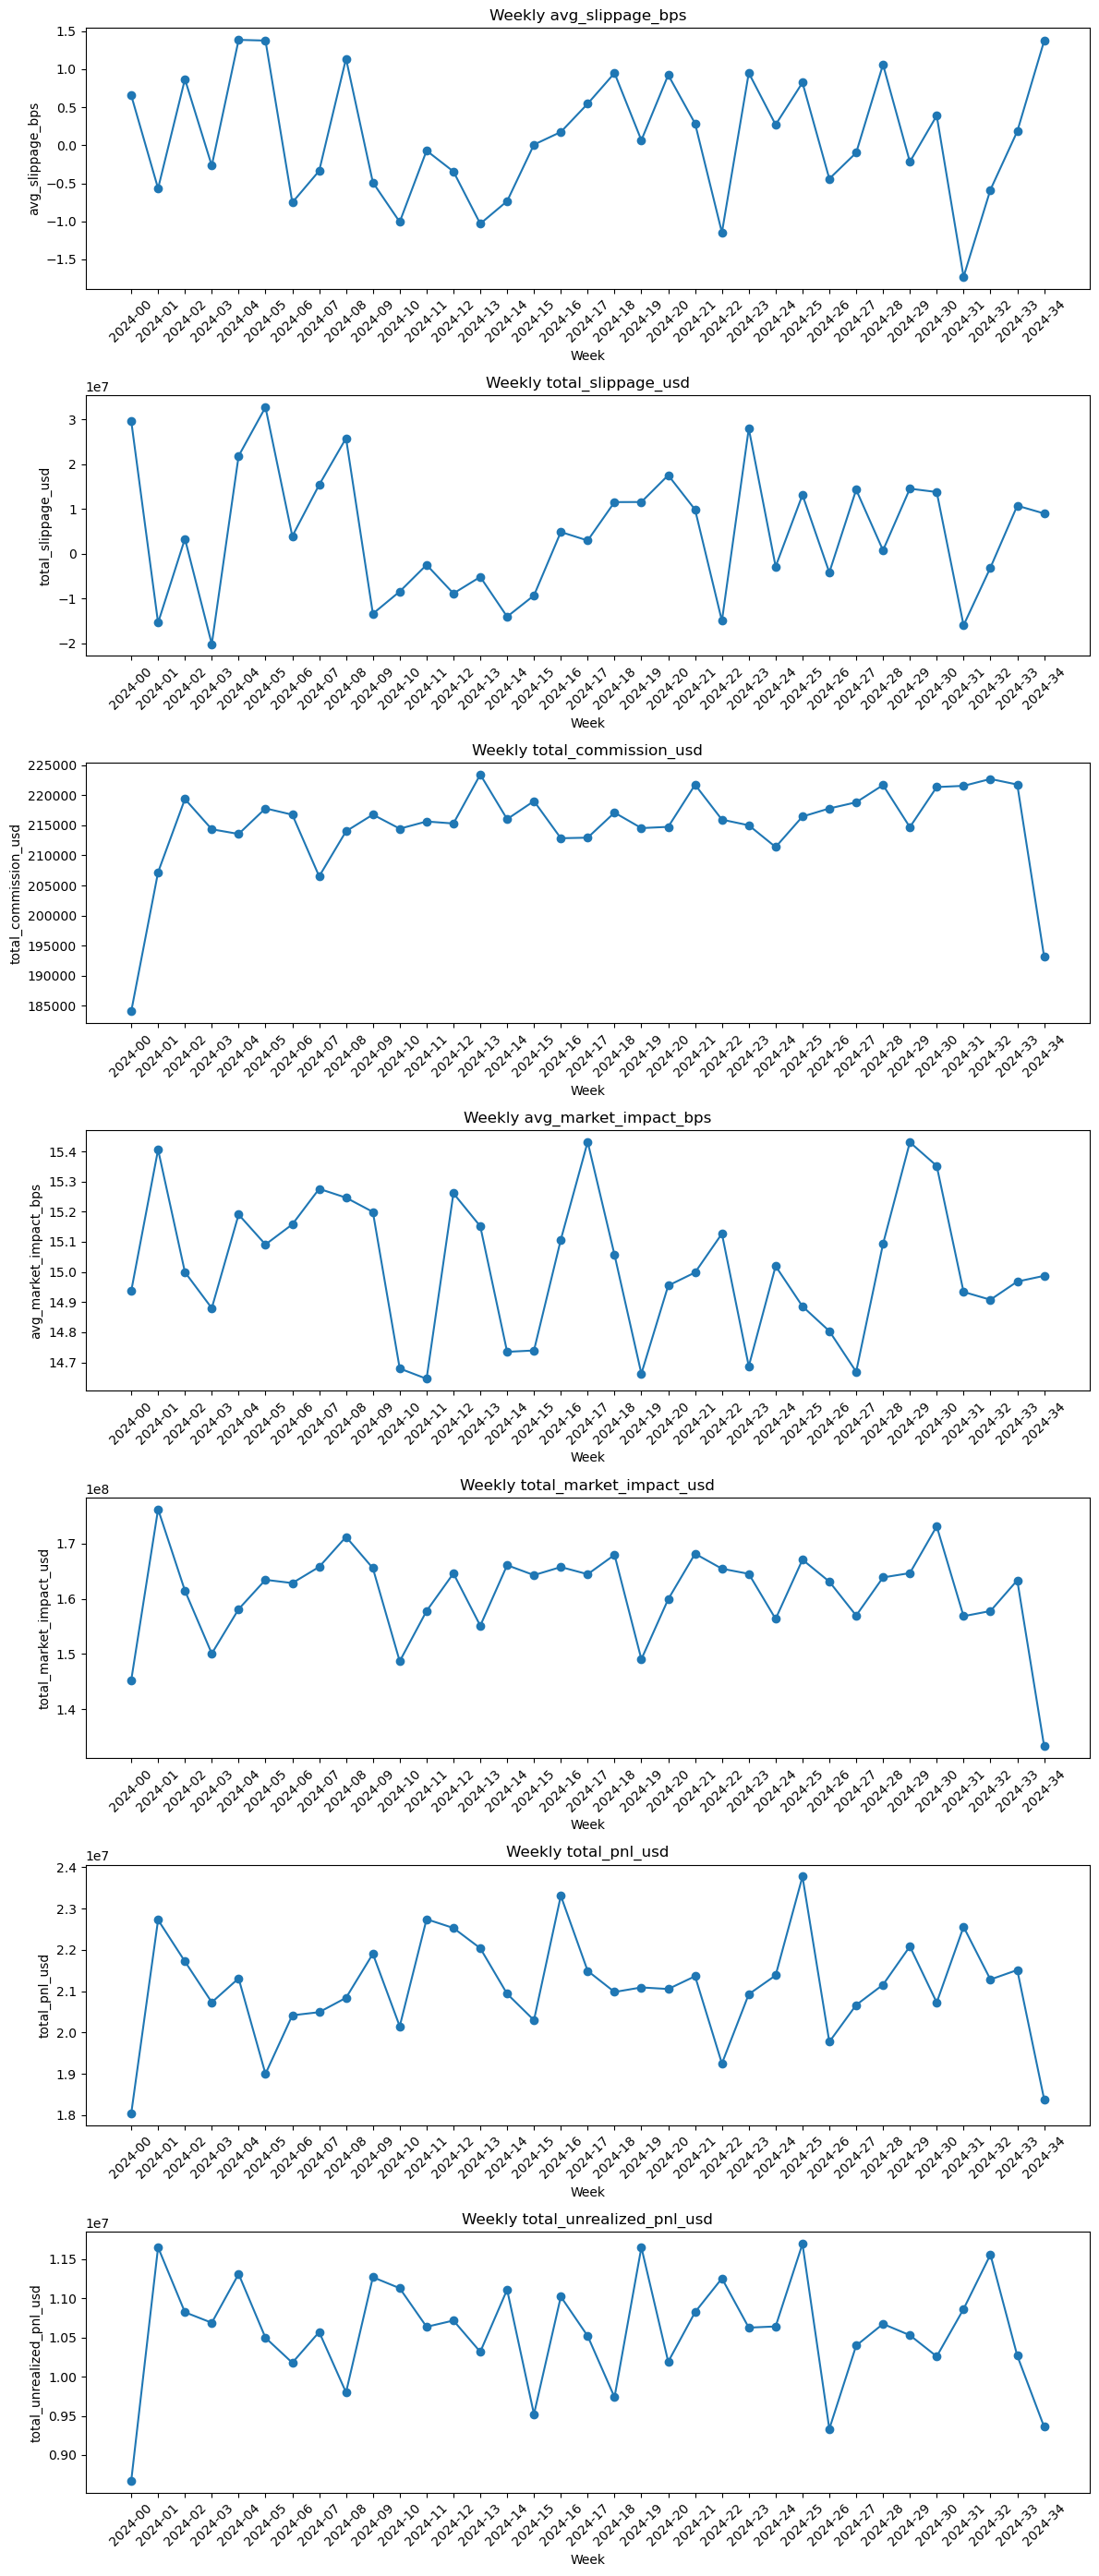

In [55]:
metrics = ['avg_slippage_bps', 'total_slippage_usd', 'total_commission_usd', 'avg_market_impact_bps', 'total_market_impact_usd',
            'total_pnl_usd', 'total_unrealized_pnl_usd']

fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 4*len(metrics)))

for i, metric in enumerate(metrics):
    axes[i].plot(weekly['week'], weekly[metric], marker='o')
    axes[i].set_title(f"Weekly {metric}")
    axes[i].set_xlabel('Week')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()